In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

In [4]:
digits = load_digits()

X = digits.images
y = digits.target

print("Number of images:", len(X))
print("Image size:", X.shape[1:])
print("Number of classes:", len(np.unique(y)))
print("Classes:", np.unique(y))

Number of images: 1797
Image size: (8, 8)
Number of classes: 10
Classes: [0 1 2 3 4 5 6 7 8 9]


In [5]:
class_counts = np.bincount(y)

for digit, count in enumerate(class_counts):
    print("Digit", digit, ":", count, "images")
    

Digit 0 : 178 images
Digit 1 : 182 images
Digit 2 : 177 images
Digit 3 : 183 images
Digit 4 : 181 images
Digit 5 : 182 images
Digit 6 : 181 images
Digit 7 : 179 images
Digit 8 : 174 images
Digit 9 : 180 images


In [6]:
print("Missing values:", np.isnan(X).sum())

X_flat = X.reshape(len(X), -1)

print("Duplicate images:", len(X_flat) - len(np.unique(X_flat, axis=0)))

Missing values: 0
Duplicate images: 0


In [7]:
print("Minimum label:", y.min())
print("Maximum label:", y.max())
print("Unique labels:", np.unique(y))

if set(np.unique(y)) == set(range(10)):
    print("Labels are valid: 0 to 9")
else:
    print("There may be an invalid label")

Minimum label: 0
Maximum label: 9
Unique labels: [0 1 2 3 4 5 6 7 8 9]
Labels are valid: 0 to 9


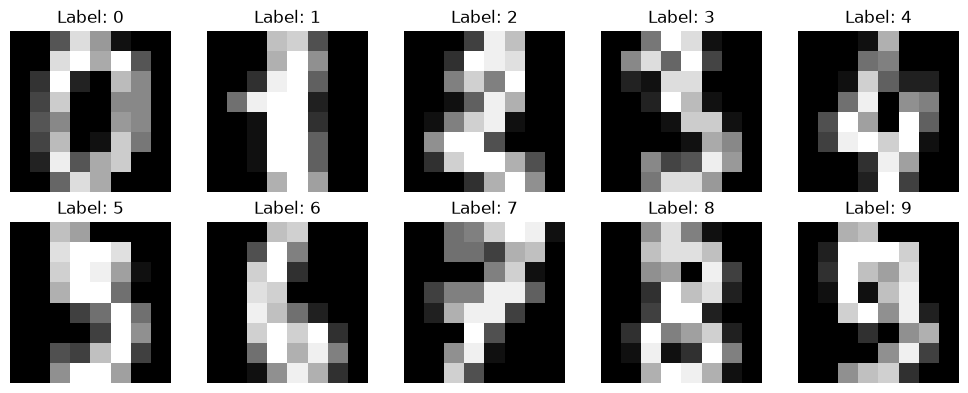

In [8]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i], cmap="gray")
    plt.title("Label: " + str(y[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
X = X / 16.0

X = X.reshape(-1, 8, 8, 1)

print("New image shape:", X.shape)
print("Pixel value range:", X.min(), "to", X.max())

New image shape: (1797, 8, 8, 1)
Pixel value range: 0.0 to 1.0


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1437, 8, 8, 1)
Testing data: (360, 8, 8, 1)


In [12]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Conv2D(16, (3, 3), activation="relu", padding="same", input_shape=(8, 8, 1)),
    MaxPooling2D((2, 2)),
    
    Conv2D(32, (3, 3), activation="relu", padding="same"),
    MaxPooling2D((2, 2)),
    
    Flatten(),
    Dense(10, activation="softmax")
])

model.summary()

/opt/anaconda3/envs/week3/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 16)       │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,090 (23.79 KB)

 Trainable params: 6,090 (23.79 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [14]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3386 - loss: 2.2108 - val_accuracy: 0.3507 - val_loss: 2.1149
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6449 - loss: 1.8902 - val_accuracy: 0.6597 - val_loss: 1.6886
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8346 - loss: 1.3197 - val_accuracy: 0.8056 - val_loss: 1.0533
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8738 - loss: 0.7708 - val_accuracy: 0.8889 - val_loss: 0.6070
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9121 - loss: 0.4813 - val_accuracy: 0.8958 - val_loss: 0.4320
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9208 - loss: 0.3473 - val_accuracy: 0.9062 - val_loss: 0.3345
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9382 - loss: 0.2708 - val_accuracy: 0.9236 - val_loss: 0.2864
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9417 - loss: 0.2332 - val_accuracy: 0.9375 - val_loss:

In [15]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 0.18600106239318848
Test Accuracy: 0.9472222328186035


In [16]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(y_test, y_pred_classes))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.85      0.78      0.81        36
           2       0.97      1.00      0.99        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       0.95      1.00      0.97        37
           6       0.92      0.97      0.95        36
           7       0.95      1.00      0.97        36
           8       0.97      0.83      0.89        35
           9       0.92      0.94      0.93        36

    accuracy                           0.95       360
   macro avg       0.95      0.95      0.95       360
weighted avg       0.95      0.95      0.95       360



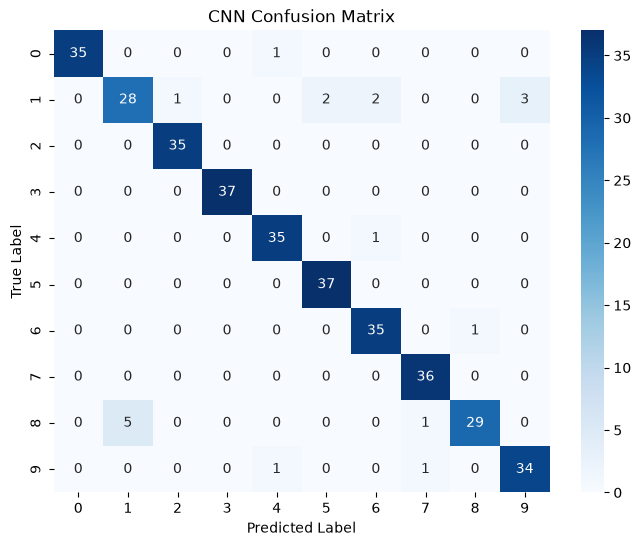

In [17]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN Confusion Matrix")
plt.show()

Number of incorrect predictions: 19


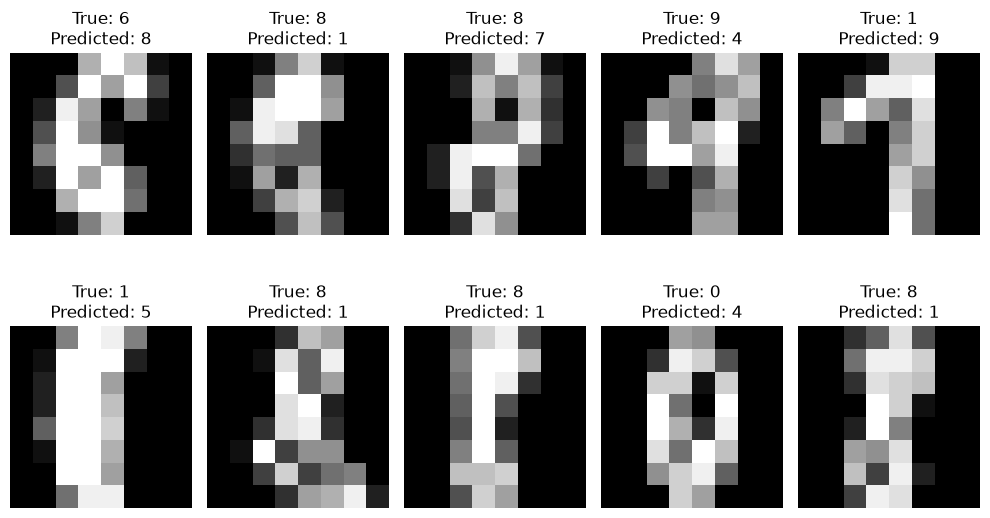

In [18]:
incorrect = np.where(y_pred_classes != y_test)[0]

print("Number of incorrect predictions:", len(incorrect))

plt.figure(figsize=(10, 6))

for i in range(min(10, len(incorrect))):
    index = incorrect[i]
    
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[index].reshape(8, 8), cmap="gray")
    plt.title("True: " + str(y_test[index]) + 
              "\nPredicted: " + str(y_pred_classes[index]))
    plt.axis("off")

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Actual digit: 5
Predicted digit: 5


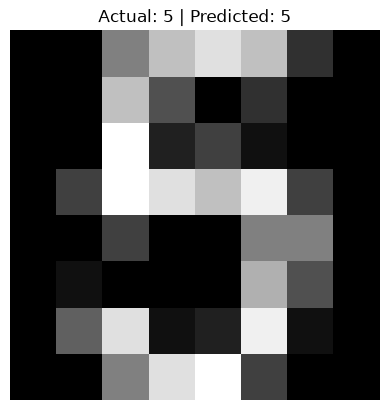

In [19]:
index = 0

sample_image = X_test[index]
actual_label = y_test[index]

prediction = model.predict(sample_image.reshape(1, 8, 8, 1))
predicted_label = np.argmax(prediction)

print("Actual digit:", actual_label)
print("Predicted digit:", predicted_label)

plt.imshow(sample_image.reshape(8, 8), cmap="gray")
plt.title("Actual: " + str(actual_label) + 
          " | Predicted: " + str(predicted_label))
plt.axis("off")
plt.show()

In [20]:
model.save("week3_2_digits_cnn.keras")

print("Week 3.2 model saved successfully!")

Week 3.2 model saved successfully!
